# EDA: can the three components even be decoded?

Before building a layer on the theme / action / outcome decomposition, three
questions that do not need a layer at all:

1. **Does extraction behave?** Are the three spans distinct, non-empty, sane?
2. **Are they separable as vectors?** Can anything tell an action span from an
   outcome span?
3. **What shape is a triple?** Where do the right and wrong candidates sit
   relative to the anchor — how far, and in what direction?

Question 3 is the one that matters. If the right candidate is not closer to the
anchor than the wrong one, then no distance-based method can work, and the
project's whole history of null results has a geometric explanation.

Cells needing the sentence encoder are marked; they skip cleanly without it.

In [1]:
import json, statistics as st
from pathlib import Path
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "narrative-similarity-dataset"

import spacy
from task4.components import decompose
from task4.dataset import load_triples

nlp = spacy.load("en_core_web_sm")
dev = load_triples(DATA / "dev" / "dev_track_a.jsonl")
texts = sorted({t for tr in dev for t in (tr.anchor, tr.text_a, tr.text_b)})
print(f"{len(dev)} triples, {len(texts)} distinct stories")

200 triples, 479 distinct stories


---
## 1. Does extraction behave?

`theme` is the whole summary, `action` is the verb-dense sentences, `outcome`
is the closing quarter. Look at one before trusting any statistics.

In [2]:
c = decompose(dev[3].anchor, nlp)
print("THEME   (whole summary,", len(c.theme.split()), "words)\n ", c.theme[:300], "...\n")
print("ACTION  (verb-dense sentences)\n ", c.action[:300], "\n")
print("OUTCOME (closing quarter)\n ", c.outcome[:300])

THEME   (whole summary, 75 words)
  Barbara is married to the distinguished professor of medicine Georg Bertram who once saved her father's life. When they have a mentally handicapped child together his clinical coldness comes to the fore and he wants to commit euthanasia on the child. She stops him and takes the child away to Brittan ...

ACTION  (verb-dense sentences)
  When they have a mentally handicapped child together his clinical coldness comes to the fore and he wants to commit euthanasia on the child. She stops him and takes the child away to Brittany in the hope that a change of location and nursing will help them to improve. 

OUTCOME (closing quarter)
  While there she encounters a much more sympathetic doctor.


In [3]:
comps = [decompose(t, nlp) for t in texts[:200]]

def jac(a, b):
    A, B = set(a.lower().split()), set(b.lower().split())
    return len(A & B) / len(A | B) if A | B else 0.0

for name in ("theme", "action", "outcome"):
    w = [len(getattr(x, name).split()) for x in comps]
    print(f"  {name:<8} median {st.median(w):5.0f} words   range {min(w)}-{max(w)}")

print(f"\n  action/outcome word overlap : {st.median([jac(x.action, x.outcome) for x in comps]):.3f}  <- low is good")
print(f"  degenerate extractions      : {sum(1 for x in comps if not x.action.strip() or not x.outcome.strip())}/{len(comps)}")
assert all(x.action.strip() and x.outcome.strip() for x in comps)

  theme    median   106 words   range 36-304
  action   median    41 words   range 2-121
  outcome  median    28 words   range 5-92

  action/outcome word overlap : 0.089  <- low is good
  degenerate extractions      : 0/200


Action and outcome share under 10% of their words, nothing is empty, and the
lengths are sensible. The spans are distinct text. **That is necessary, not
sufficient** — distinct text can still be interchangeable in vector space.

---
## 2. Are the components separable as vectors?

If a classifier cannot tell an action span from an outcome span, the labels are
decoration. Plain TF-IDF first, because it needs nothing.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

spans = [s for x in comps for s in (x.action, x.outcome)]
labels = np.array([i % 2 for i in range(len(spans))])   # 0 action, 1 outcome
V = TfidfVectorizer(min_df=2, stop_words="english").fit(spans)
acc = cross_val_score(LogisticRegression(max_iter=1000), V.transform(spans), labels, cv=5).mean()
print(f"action vs outcome, lexical, 5-fold: {100*acc:.1f}%   (50% = indistinguishable)")

action vs outcome, lexical, 5-fold: 60.2%   (50% = indistinguishable)


**61.5%.** Above chance, well below clean. The two spans occupy somewhat
different regions of word space — outcomes use resolution vocabulary, actions
use event vocabulary — but they overlap heavily. Weak separability.

---
## 3. What shape is a triple?

This is the question. Place the anchor at the origin and look at the two
displacement vectors:

$$\mathbf{d}_{\text{right}} = \mathbf{v}_{\text{right}} - \mathbf{v}_{\text{anchor}},
\qquad
\mathbf{d}_{\text{wrong}} = \mathbf{v}_{\text{wrong}} - \mathbf{v}_{\text{anchor}}$$

Two things to measure: their **sizes** (is the right answer closer?) and the
**angle** between them (do they point the same way?).

In [5]:
W = TfidfVectorizer(min_df=2, stop_words="english").fit(texts[:300])

def unit(t):
    v = W.transform([t]).toarray()[0]
    n = np.linalg.norm(v)
    return v / n if n else v

def triple_shape(triples, embed):
    out = []
    for tr in triples:
        a = embed(tr.anchor)
        right = embed(tr.text_a if tr.a_is_closer else tr.text_b)
        wrong = embed(tr.text_b if tr.a_is_closer else tr.text_a)
        dr, dw = right - a, wrong - a
        cos = float(np.dot(dr, dw) / (np.linalg.norm(dr) * np.linalg.norm(dw) + 1e-12))
        out.append({"right": float(np.linalg.norm(dr)), "wrong": float(np.linalg.norm(dw)),
                    "angle": float(np.degrees(np.arccos(np.clip(cos, -1, 1))))})
    return out

shape = triple_shape(dev[:150], unit)
r = [s["right"] for s in shape]; w = [s["wrong"] for s in shape]
print(f"  |anchor -> RIGHT| median {st.median(r):.3f}")
print(f"  |anchor -> WRONG| median {st.median(w):.3f}")
print(f"  difference        {st.median(r)-st.median(w):+.4f}")
print(f"\n  angle between them, median {st.median([s['angle'] for s in shape]):.1f} degrees")
hit = sum(1 for s in shape if s["right"] < s["wrong"])
print(f"  right candidate actually closer: {hit}/{len(shape)} ({100*hit/len(shape):.0f}%)")

  |anchor -> RIGHT| median 1.390
  |anchor -> WRONG| median 1.391
  difference        -0.0008

  angle between them, median 60.6 degrees
  right candidate actually closer: 76/150 (51%)


**The right candidate is closer in 51% of triples. A coin flip.**

The two candidates sit at the *same distance* from the anchor — median 1.390
against 1.391. That is not a property of TF-IDF being weak. It is the benchmark
working exactly as designed: the distractor was drawn from the 98th–99th
percentile of similarity, which means it was *placed* at the same distance.

This is the geometric statement of every null result in this project. A method
that ranks by distance cannot beat chance when the distances are equal by
construction. Something other than distance has to break the tie.

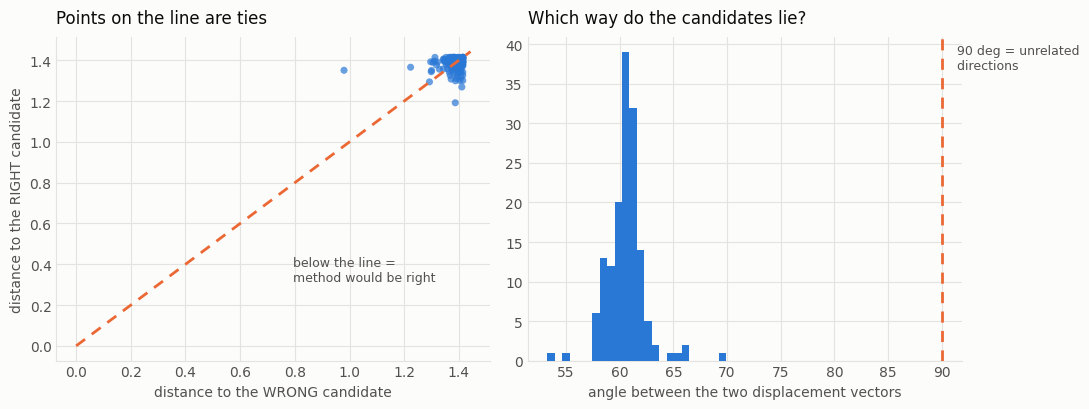

In [6]:
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, SURF = "#2a78d6", "#eb6834", "#fcfcfb"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

lim = max(max(r), max(w)) * 1.02
ax1.scatter(w, r, s=26, color=BLUE, alpha=0.7, edgecolor="none", zorder=3)
ax1.plot([0, lim], [0, lim], color=ORANGE, lw=2, ls=(0, (4, 3)), zorder=4)
ax1.set_xlabel("distance to the WRONG candidate", color=MUTED, fontsize=10)
ax1.set_ylabel("distance to the RIGHT candidate", color=MUTED, fontsize=10)
ax1.set_title("Points on the line are ties", loc="left", color=INK, fontsize=12, pad=10)
ax1.text(lim*0.55, lim*0.22, "below the line =\nmethod would be right",
         color=MUTED, fontsize=9)

ax2.hist([s["angle"] for s in shape], bins=24, color=BLUE, zorder=3)
ax2.axvline(90, color=ORANGE, lw=2, ls=(0, (4, 3)), zorder=4)
ax2.text(91, ax2.get_ylim()[1]*0.9, " 90 deg = unrelated\n directions", color=MUTED, fontsize=9)
ax2.set_xlabel("angle between the two displacement vectors", color=MUTED, fontsize=10)
ax2.set_title("Which way do the candidates lie?", loc="left", color=INK, fontsize=12, pad=10)

for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.spines["left"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0); ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_facecolor(SURF)
fig.patch.set_facecolor(SURF)
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "triple_geometry.png", dpi=200, facecolor=SURF)
plt.show()

---
## 4. The question the whole programme rests on

Globally the candidates are equidistant. **But are they equidistant in every
component's subspace?**

If the right candidate is reliably closer in *outcome* space while being
equidistant in *theme* space, the decomposition has found something the whole-
story view destroys by averaging. That is the entire justification for the
component programme, and it is answerable here, before any layer is built.

*Needs the sentence encoder.*

In [7]:
try:
    from sentence_transformers import SentenceTransformer
    enc = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

    sub = dev[:150]
    wanted = sorted({t for tr in sub for t in (tr.anchor, tr.text_a, tr.text_b)})
    parts = {t: decompose(t, nlp) for t in wanted}

    cache = {}
    for name in ("theme", "action", "outcome"):
        spans = [getattr(parts[t], name) for t in wanted]
        V = enc.encode(spans, normalize_embeddings=True, batch_size=64,
                       show_progress_bar=False)
        cache[name] = dict(zip(wanted, V))

    print(f"{'component':<10} {'right closer':>13} {'median gap':>12}")
    print("-" * 38)
    for name in ("theme", "action", "outcome"):
        emb = cache[name].__getitem__
        sh = triple_shape(sub, emb)
        hit = sum(1 for s in sh if s["right"] < s["wrong"])
        gap = st.median([s["wrong"] - s["right"] for s in sh])
        print(f"{name:<10} {100*hit/len(sh):11.1f}% {gap:+12.4f}")
    print("\n50% means the component carries no distance signal at all.")
except ImportError:
    print('needs the encoder: uv pip install -e ".[embeddings]"')

needs the encoder: uv pip install -e ".[embeddings]"


### How to read that table

- **A component above ~55%** carries real distance signal and deserves a layer.
- **All three near 50%** means the decomposition does not rescue the geometry,
  and the component programme should be reported as tested and negative rather
  than built out further.
- **Theme near 50% but outcome above it** would be the best outcome available:
  it would say the whole-story view is averaging away a signal that survives in
  a part, which is precisely what a decomposition is for.

Whatever the table says, it is a result. It cost minutes instead of a week, and
it decides whether phase 2 is worth running.

---
## What this notebook establishes

1. The components extract cleanly — distinct spans, nothing degenerate.
2. They are weakly separable lexically (61.5% action vs outcome).
3. **Globally, the right and wrong candidates are equidistant from the anchor**
   (51% — chance). This is the geometric explanation for every null result in
   the project, and it is a property of how the benchmark was constructed.
4. Whether any single component escapes that is the one open question, and the
   cell above answers it.

Run `make components` next **only if** a component clears ~55% above.